# 04 · Every Sentinel-2 band, every month: is there more signal than SAG?

**Author:** Meera Mehta, MIT Analytics Lab × Cropin, Nov 2026
**Inputs:**
- `data/gee_exports/ref_s2_bands_by_month_{PR,SC,RS}.csv` and `qc_s2_bands_by_month.csv`
  (from `gee/05_s2_bands_by_month_export.js`);
- `data/processed/mapbiomas_ref_south.csv` (point locations) and the notebook-01 QC inputs
  (polygon locations, for spatial blocks and removing repeats).

**Outputs:** `figures/04*.png`

**Why this notebook.** At the 11/4 meeting Deepak asked us not to stop at SAG and NDVI, which use
only 3–4 of Sentinel-2's bands. He asked us to look at the **whole spectrum**, especially the two
shortwave-infrared bands **B11 and B12 (SWIR)**, and to compare **December–January with the other
months**. That way the report can answer "why only this index?"

**What we measure.** For each of the 10 surface bands, and for SAG as a benchmark, we take the median
reflectance in each calendar month, pooled over 2019–2022. That gives one value per point (or polygon),
band and month. Then we ask, for each cell of that band × month grid, how well the value alone separates
plantation from forest.

**Two labelled sets, as in notebook 03:**
- **MapBiomas reference points** (2,290; 528 plantation, 1,762 forest): an independent landscape sample.
  This is the main test.
- **Cropin QC polygons** (433, minus 13 repeated rows = 420): the real alerts, but a small sample chosen in
  a way we don't know. Everything on this set is exploratory.

**How to read the numbers.**
- **AUC** (area under the ROC curve) is the chance that a randomly chosen plantation and a randomly chosen
  forest are put in the right order by the value. 0.5 is a coin flip and 1.0 is perfect separation. We
  report it oriented, so it's always ≥ 0.5, and say whether the value is *higher* or *lower* in plantations.
- **p-value** (Mann–Whitney U test): how surprising the gap between the two groups would be if there were no
  real difference. We test 180 cells, so some would look significant by luck. The **Holm correction**
  adjusts the p-values for that, and we call a cell significant only if its Holm-adjusted p < 0.05.
- **95% CI**: the range the AUC would likely fall in on a fresh sample (2,000 bootstrap resamples).

In [1]:
import sys, warnings, glob
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from qc_analysis import *

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="Mean of empty slice", category=RuntimeWarning)
set_style()
SEED, N_BOOT = 0, 2000
np.random.seed(SEED)
pd.set_option("display.precision", 3, "display.width", 160)

BANDS = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
NAME = {"B2": "B2 blue", "B3": "B3 green", "B4": "B4 red", "B5": "B5 red edge 1", "B6": "B6 red edge 2",
        "B7": "B7 red edge 3", "B8": "B8 near-infrared", "B8A": "B8A narrow NIR", "B11": "B11 SWIR-1",
        "B12": "B12 SWIR-2", "SAG": "SAG (Cropin)", "NDVI": "NDVI", "NDRE": "NDRE (red edge)",
        "NDMI": "NDMI (moisture)", "NBR": "NBR (burn ratio)"}
INDICES = {"NDVI": ("B8", "B4"), "NDRE": ("B8A", "B5"), "NDMI": ("B8", "B11"), "NBR": ("B8", "B12")}
ROWS = BANDS + ["SAG"] + list(INDICES)
MONTHS = [7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6]          # Jul → Jun, so the southern summer sits mid-axis
MLAB = dict(zip(range(1, 13), "Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split()))
OCTJAN, WINTER = [10, 11, 12, 1], [4, 5, 6, 7, 8, 9]       # Cropin's SAG season; Apr–Sep
col = lambda b, m: f"{b}_{m:02d}"

def add_indices(d):
    # Normalised differences built from the monthly band medians. Note: an index of medians is close
    # to, but not the same as, the median of per-image indices.
    d = d.copy()
    for name, (a, b) in INDICES.items():
        for m in range(1, 13):
            x, y = d[col(a, m)], d[col(b, m)]
            d[col(name, m)] = (x - y) / (x + y)
    return d

REF_FILES = sorted(glob.glob(str(DATA / "gee_exports/ref_s2_bands_by_month_*.csv")))
assert len(REF_FILES) == 3, f"expected 3 ref files (PR, SC, RS), found {len(REF_FILES)}: run gee/05"

## (i) Data
Each reference point is a 15 m circle (about 3×3 pixels), as in notebook 03. Each QC polygon is averaged
over its own pixels. Months pool four years (2019–2022), which is before the QC clearings (2026) and
inside the years when the reference labels are stable. That gives each month enough clear images, even in
the cloudy winter.

In [2]:
ref = pd.concat([pd.read_csv(f) for f in REF_FILES]).set_index("id")
pts = pd.read_csv(DATA / "processed/mapbiomas_ref_south.csv").set_index("id")
assert ref.index.is_unique and set(ref.index) == set(pts.index), "reference ids do not match the subset"
assert (ref.label == pts.loc[ref.index, "label"]).all(), "labels differ from the reference subset"
ref = add_indices(ref.join(pts[["lat", "lon"]]))
ref["y"] = (ref.label == "plantation").astype(int)

qc_raw = pd.read_csv(DATA / "gee_exports/qc_s2_bands_by_month.csv")
qc = load_qc()[["id", "qc_label", "lat", "lon", "area_m2"]].merge(
    qc_raw.drop(columns="qc_label"), on="id", how="inner", validate="one_to_one")
assert len(qc) == 433, "QC rows missing"
qc = add_indices(dedupe(qc).set_index("id"))
qc["y"] = (qc.qc_label == "plantation").astype(int)

for nm, d in [("reference", ref), ("QC", qc)]:
    n = d[[col("n", m) for m in range(1, 13)]]
    vals = d[[col(b, m) for b in ROWS for m in range(1, 13)]]
    print(f"{nm}: {len(d):,} ({int(d.y.sum())} plantation, {int((d.y == 0).sum())} forest) | "
          f"clear images per month, median {n.median().min():.0f}–{n.median().max():.0f} | "
          f"missing values: {100 * vals.isna().mean().max():.1f}% in the worst column")

reference: 2,290 (528 plantation, 1762 forest) | clear images per month, median 9–15 | missing values: 3.9% in the worst column
QC: 420 (302 plantation, 118 forest) | clear images per month, median 7–12 | missing values: 3.1% in the worst column


## (ii) The band × month grid
For every band and month, AUC and Holm-adjusted p-value, on each set separately. In the heatmap:
- darker burgundy means better separation;
- ↑ means the value is higher in plantations, ↓ lower;
- grey text means not significant after the Holm correction;
- the box marks Oct–Jan, the season Cropin uses for SAG.

ref: 131/180 cells significant after Holm; best cell SAG Nov AUC 0.89
qc: 122/180 cells significant after Holm; best cell SAG Nov AUC 0.88


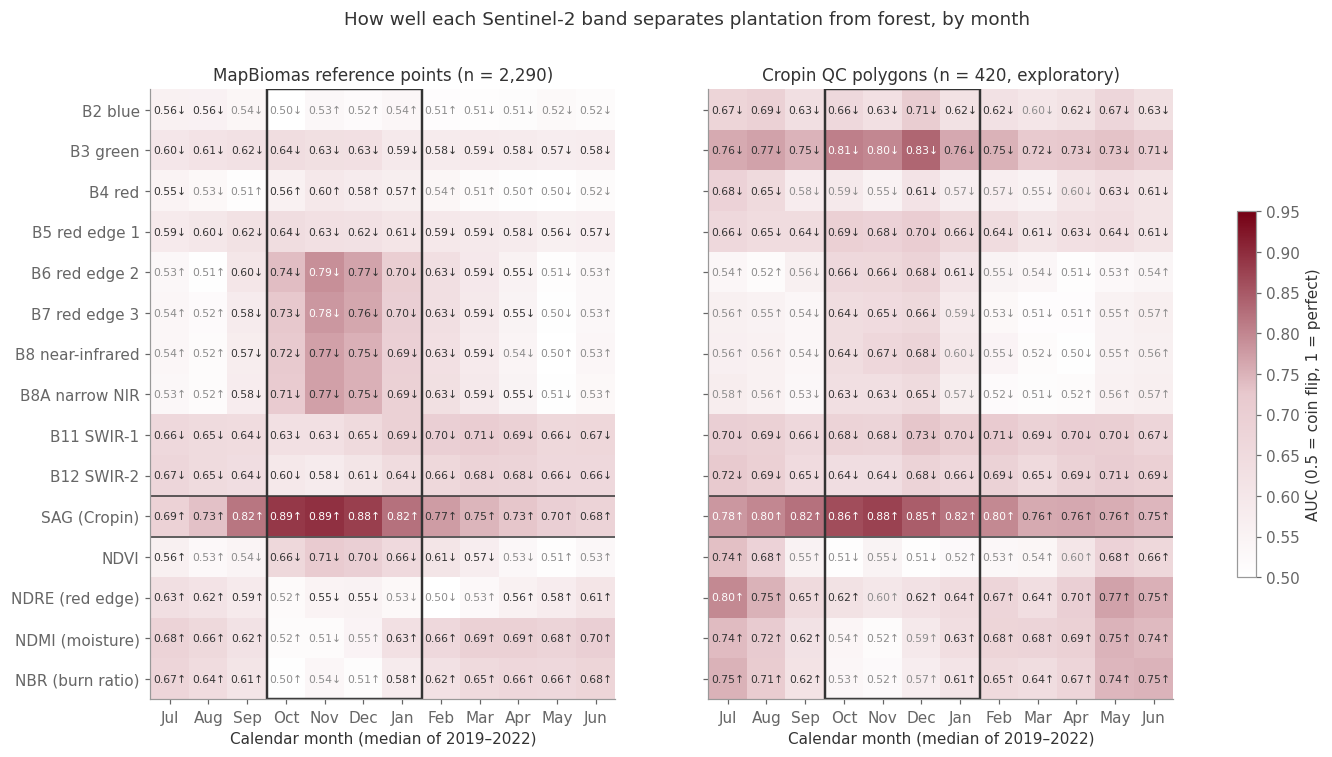

In [3]:
def grid(d):
    out = []
    for b in ROWS:
        for m in range(1, 13):
            s = d[[col(b, m), "y"]].dropna()
            x, y = s[col(b, m)].values, s.y.values
            raw = roc_auc_score(y, x)
            out.append(dict(row=b, month=m, raw_auc=raw, auc=max(raw, 1 - raw), higher=raw >= 0.5,
                            p=mwu_test(x[y == 1], x[y == 0]), n=len(s)))
    g = pd.DataFrame(out)
    g["p_holm"] = holm(g.p)
    g["sig"] = g.p_holm < 0.05
    return g

G = {"ref": grid(ref), "qc": grid(qc)}
for k, g in G.items():
    print(f"{k}: {int(g.sig.sum())}/{len(g)} cells significant after Holm; best cell "
          f"{g.loc[g.auc.idxmax(), 'row']} {MLAB[g.loc[g.auc.idxmax(), 'month']]} AUC {g.auc.max():.2f}")

CMAP = LinearSegmentedColormap.from_list("burg", ["#FFFFFF", "#E8C9CE", PAL["plantation"]])

def heatmap(ax, g, title):
    M = g.pivot(index="row", columns="month", values="auc").loc[ROWS, MONTHS]
    H = g.pivot(index="row", columns="month", values="higher").loc[ROWS, MONTHS]
    S = g.pivot(index="row", columns="month", values="sig").loc[ROWS, MONTHS]
    im = ax.imshow(M.values, cmap=CMAP, vmin=0.5, vmax=0.95, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            c = PAL["grey"] if not S.values[i, j] else ("white" if v > 0.78 else PAL["ink"])
            ax.text(j, i, f"{v:.2f}{'↑' if H.values[i, j] else '↓'}", ha="center", va="center", fontsize=7, color=c)
    ax.set_xticks(range(12), [MLAB[m] for m in MONTHS])
    ax.set_yticks(range(len(ROWS)), [NAME[r] for r in ROWS])
    ax.grid(False)
    for y in [len(BANDS) - 0.5, len(BANDS) + 0.5]:
        ax.axhline(y, color=PAL["ink"], lw=1)
    j0 = MONTHS.index(10)
    ax.add_patch(plt.Rectangle((j0 - 0.5, -0.5), 4, len(ROWS), fill=False, ec=PAL["ink"], lw=1.6))
    ax.set_xlabel("Calendar month (median of 2019–2022)")
    ax.set_title(title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(15, 7.2), sharey=True)
heatmap(axes[0], G["ref"], f"MapBiomas reference points (n = {len(ref):,})")
im = heatmap(axes[1], G["qc"], f"Cropin QC polygons (n = {len(qc)}, exploratory)")
fig.colorbar(im, ax=axes, shrink=0.6, label="AUC (0.5 = coin flip, 1 = perfect)")
fig.suptitle("How well each Sentinel-2 band separates plantation from forest, by month", x=0.45, y=0.98)
savefig(fig, "04a_band_month_auc_heatmap")
plt.show()

### Best month per band, and Dec–Jan
For each row we pick the best month **on the reference points only**, then read the QC AUC in that same
month. So the QC column is not chosen to look good. The 95% CIs are for those best-month cells. "Dec–Jan"
is the average AUC of the December and January cells.

In [4]:
rows = []
for b in ROWS:
    gr, gq = G["ref"][G["ref"].row == b].set_index("month"), G["qc"][G["qc"].row == b].set_index("month")
    m = int(gr.auc.idxmax())
    _, lo_r, hi_r = auc_ci(*ref[[ "y", col(b, m)]].dropna().T.values, n_boot=N_BOOT, seed=SEED)
    _, lo_q, hi_q = auc_ci(*qc[["y", col(b, m)]].dropna().T.values, n_boot=N_BOOT, seed=SEED)
    rows.append({"row": NAME[b], "best month (ref)": MLAB[m],
                 "ref AUC": gr.auc[m], "ref 95% CI": f"{lo_r:.2f}–{hi_r:.2f}",
                 "ref Dec–Jan": gr.auc[[12, 1]].mean(),
                 "QC AUC (same month)": gq.auc[m], "QC 95% CI": f"{lo_q:.2f}–{hi_q:.2f}",
                 "QC Dec–Jan": gq.auc[[12, 1]].mean(),
                 "direction": "higher in plantations" if gr.higher[m] else "lower in plantations",
                 "same direction on QC": bool(gr.higher[m] == gq.higher[m])})
best = pd.DataFrame(rows).set_index("row")
best

,best month (ref),ref AUC,ref 95% CI,ref Dec–Jan,QC AUC (same month),QC 95% CI,QC Dec–Jan,direction,same direction on QC
row,,,,,,,,,
B2 blue,Jul,0.558,0.53–0.59,0.527,0.674,0.62–0.73,0.664,lower in plantations,True
B3 green,Oct,0.641,0.61–0.67,0.608,0.807,0.76–0.85,0.798,lower in plantations,True
B4 red,Nov,0.595,0.56–0.63,0.577,0.553,0.49–0.61,0.591,higher in plantations,False
B5 red edge 1,Oct,0.639,0.61–0.67,0.615,0.695,0.64–0.75,0.683,lower in plantations,True
B6 red edge 2,Nov,0.790,0.77–0.81,0.735,0.662,0.60–0.72,0.646,lower in plantations,True
B7 red edge 3,Nov,0.781,0.76–0.80,0.730,0.646,0.59–0.71,0.621,lower in plantations,True
B8 near-infrared,Nov,0.771,0.75–0.79,0.722,0.665,0.61–0.72,0.636,lower in plantations,True
B8A narrow NIR,Nov,0.771,0.75–0.79,0.722,0.631,0.57–0.69,0.611,lower in plantations,True
B11 SWIR-1,Mar,0.706,0.67–0.74,0.671,0.687,0.63–0.74,0.715,lower in plantations,True


### Month-by-month profiles for the bands Deepak named
SWIR (B11, B12) next to SAG and the two indices built from them (NDMI uses B11, NBR uses B12), plus NDVI
for reference. Raw AUC is shown, so values below 0.5 mean "lower in plantations".

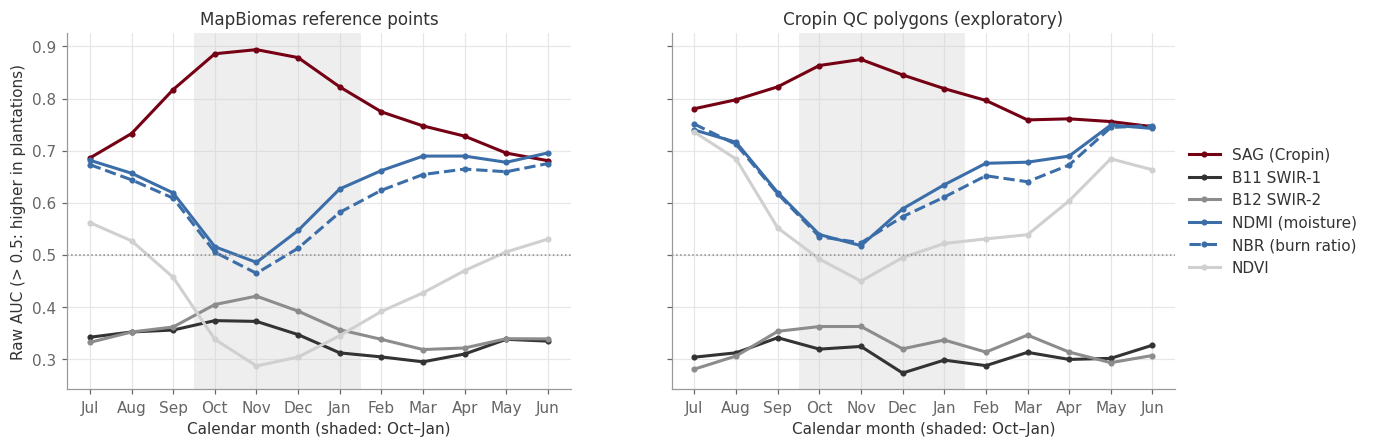

In [5]:
SHOW = [("SAG", PAL["plantation"], "-"), ("B11", PAL["ink"], "-"), ("B12", PAL["grey"], "-"),
        ("NDMI", PAL["forest"], "-"), ("NBR", PAL["forest"], "--"), ("NDVI", PAL["light"], "-")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (k, title) in zip(axes, [("ref", "MapBiomas reference points"), ("qc", "Cropin QC polygons (exploratory)")]):
    g = G[k]
    for b, c, ls in SHOW:
        s = g[g.row == b].set_index("month").raw_auc.loc[MONTHS]
        ax.plot(range(12), s.values, color=c, ls=ls, marker="o", ms=3, label=NAME[b])
    ax.axhline(0.5, color=PAL["grey"], lw=1, ls=":")
    ax.axvspan(MONTHS.index(10) - 0.5, MONTHS.index(1) + 0.5, color=PAL["light"], alpha=0.35, lw=0)
    ax.set_xticks(range(12), [MLAB[m] for m in MONTHS])
    ax.set_xlabel("Calendar month (shaded: Oct–Jan)")
    ax.set_title(title)
axes[0].set_ylabel("Raw AUC (> 0.5: higher in plantations)")
axes[1].legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
savefig(fig, "04b_swir_sag_month_profiles")
plt.show()

## (iii) Does the grid look the same on both sets?
Each dot is one band × month cell. If a cell's signal is general, it should sit in the same place on both
axes. Dots in the top-right or bottom-left quarters agree on direction.

Spearman rank correlation of raw AUC, ref vs QC: 0.78 (180 cells)
same direction: 84% of all cells; 98% of the 103 cells significant on both sets


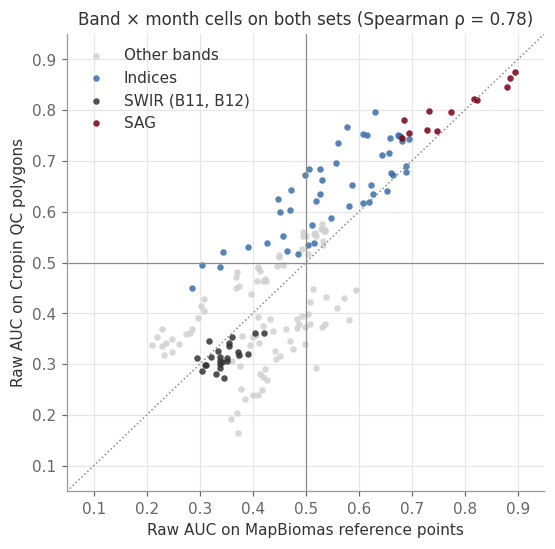

In [6]:
m = G["ref"].merge(G["qc"], on=["row", "month"], suffixes=("_ref", "_qc"))
rho = spearmanr(m.raw_auc_ref, m.raw_auc_qc).statistic
agree = (m.higher_ref == m.higher_qc)
both_sig = m.sig_ref & m.sig_qc
print(f"Spearman rank correlation of raw AUC, ref vs QC: {rho:.2f} (180 cells)")
print(f"same direction: {agree.mean():.0%} of all cells; {agree[both_sig].mean():.0%} of the "
      f"{int(both_sig.sum())} cells significant on both sets")

fig, ax = plt.subplots(figsize=(5.6, 5.4))
kind = np.where(m.row == "SAG", "SAG", np.where(m.row.isin(["B11", "B12"]), "SWIR (B11, B12)",
                np.where(m.row.isin(list(INDICES)), "Indices", "Other bands")))
for k, c in [("Other bands", PAL["light"]), ("Indices", PAL["forest"]), ("SWIR (B11, B12)", PAL["ink"]), ("SAG", PAL["plantation"])]:
    s = m[kind == k]
    ax.scatter(s.raw_auc_ref, s.raw_auc_qc, s=18, color=c, label=k, alpha=0.85, linewidths=0)
ax.plot([0, 1], [0, 1], color=PAL["grey"], lw=1, ls=":")
ax.axhline(0.5, color=PAL["grey"], lw=0.8); ax.axvline(0.5, color=PAL["grey"], lw=0.8)
ax.set_xlim(0.05, 0.95); ax.set_ylim(0.05, 0.95)
ax.set_xlabel("Raw AUC on MapBiomas reference points")
ax.set_ylabel("Raw AUC on Cropin QC polygons")
ax.set_title(f"Band × month cells on both sets (Spearman ρ = {rho:.2f})")
ax.legend(loc="upper left")
savefig(fig, "04c_ref_vs_qc_cells")
plt.show()

## (iv) Do the other bands add anything beyond SAG?
A band can be strong on its own and still add nothing once SAG is in the model, because both may pick up
the same thing (dark canopy). We test this with the same logistic-regression model and **spatially blocked
cross-validation** as notebooks 01–03:
- 20 map blocks, and a block is never split between training and testing;
- 20 repeats (seeds 0–19);
- the cutoff that hides ≤ 5% of forest is chosen *inside* each training fold (nested), then applied to the
  held-out fold.

"Caught" is the share of plantations the model would remove as false alarms. "Hidden" is the share of
real forest clearing it would wrongly remove.

To avoid picking months that happen to look good, every feature is a **fixed season average**, not a best
month: **Oct–Jan** (Cropin's SAG season) and **Apr–Sep** (winter).

In [7]:
def season(d, b, months):
    return d[[col(b, m) for m in months]].mean(axis=1)

def season_table(d):
    f = pd.DataFrame(index=d.index)
    for b in BANDS + ["SAG"]:
        f[f"{b}_octjan"] = season(d, b, OCTJAN)
        f[f"{b}_winter"] = season(d, b, WINTER)
    return f

SETS = {
    "SAG Oct–Jan only": ["SAG_octjan"],
    "+ SWIR (B11, B12) both seasons": ["SAG_octjan", "B11_octjan", "B12_octjan", "B11_winter", "B12_winter"],
    "+ all 10 bands Oct–Jan": ["SAG_octjan"] + [f"{b}_octjan" for b in BANDS],
    "+ all 10 bands both seasons": ["SAG_octjan"] + [f"{b}_{s}" for b in BANDS for s in ("octjan", "winter")],
    "All 10 bands both seasons, no SAG": [f"{b}_{s}" for b in BANDS for s in ("octjan", "winter")],
}
ALL = sorted(set(sum(SETS.values(), [])))
F = {}
for k, d in [("ref", ref), ("qc", qc)]:
    f = season_table(d).join(d[["y", "lat", "lon"]])
    n0 = len(f)
    F[k] = f.dropna(subset=ALL)
    print(f"{k}: {len(F[k])} of {n0} kept (dropped {n0 - len(F[k])} with a season that has no clear value)")

res = []
for k, f in F.items():
    groups = spatial_groups(f, k=20, seed=SEED)
    for name, cols in SETS.items():
        r, _ = cv_evaluate(f[cols].values, f.y.values, groups=groups, kind="group", seeds=range(20))
        res.append({"set": "reference" if k == "ref" else "QC", "features": name, "n features": len(cols),
                    "AUC": r.auc.mean(), "AUC range (20 seeds)": f"{r.auc.min():.2f}–{r.auc.max():.2f}",
                    "caught %": r.nest_caught.mean(), "hidden %": r.nest_hidden.mean(), "_auc": r.auc.values})
res = pd.DataFrame(res)
base = res[res.features == "SAG Oct–Jan only"].set_index("set")._auc
res["AUC gain vs SAG (same seeds)"] = [f"{np.mean(a - base[s]):+.3f} ({np.mean(a > base[s]):.0%} of seeds up)"
                                       for s, a in zip(res.set, res._auc)]
res.drop(columns="_auc").set_index(["set", "features"])

ref: 2281 of 2290 kept (dropped 9 with a season that has no clear value)
qc: 417 of 420 kept (dropped 3 with a season that has no clear value)


n features    AUC AUC range (20 seeds)  caught %  hidden % AUC gain vs SAG (same seeds)
set       features                                                                                                                  
reference SAG Oct–Jan only                            1  0.889            0.89–0.89    53.002     5.216      +0.000 (0% of seeds up)
          + SWIR (B11, B12) both seasons              5  0.895            0.89–0.90    53.939     5.191    +0.006 (100% of seeds up)
          + all 10 bands Oct–Jan                     11  0.920            0.92–0.92    69.331     5.023    +0.031 (100% of seeds up)
          + all 10 bands both seasons                21  0.933            0.93–0.94    75.583     5.028    +0.044 (100% of seeds up)
          All 10 bands both seasons, no SAG          20  0.924            0.92–0.93    74.159     4.852    +0.035 (100% of seeds up)
QC        SAG Oct–Jan only                            1  0.849            0.83–0.86    34.553     5.130      +0.000 (0% of seeds up)
          + SWIR (B11, B12) both seasons              5  0.855            0.84–0.87    39.106     5.130     +0.006 (85% of seeds up)
          + all 10 bands Oct–Jan                     11  0.913            0.91–0.92    54.983     5.739    +0.064 (100% of seeds up)
          + all 10 bands both seasons                21  0.925            0.92–0.93    61.987     5.478    +0.076 (100% of seeds up)
          All 10 bands both seasons, no SAG          20  0.906            0.90–0.91    58.858     5.609    +0.058 (100% of seeds up)

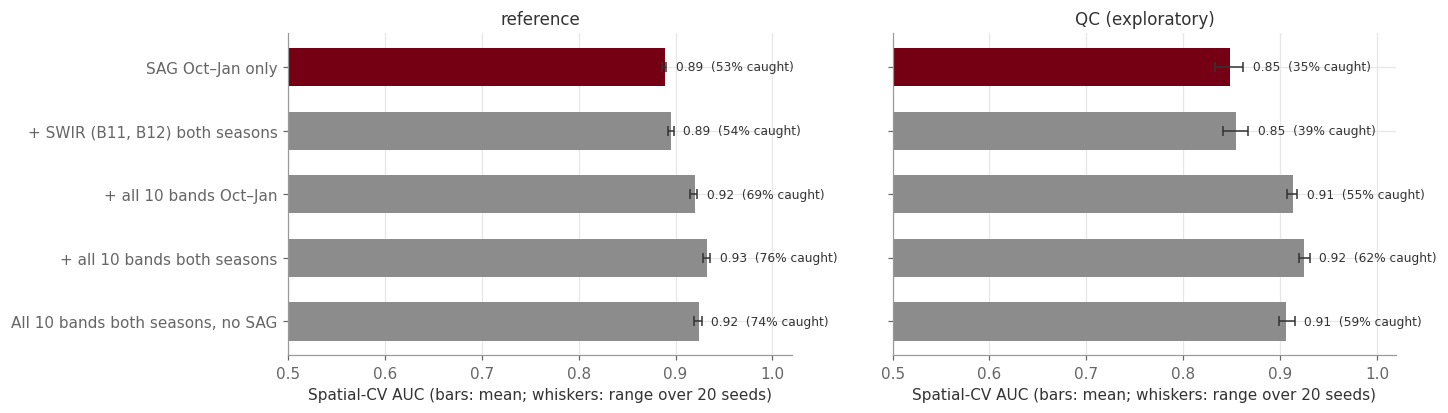

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
names = list(SETS)
for ax, s in zip(axes, ["reference", "QC"]):
    r = res[res.set == s].set_index("features").loc[names]
    lo = [a.min() for a in r._auc]; hi = [a.max() for a in r._auc]
    cols = [PAL["plantation"] if n == names[0] else PAL["grey"] for n in names]
    ax.barh(range(len(names)), r.AUC, color=cols, height=0.6)
    ax.errorbar(r.AUC, range(len(names)), xerr=[r.AUC - lo, np.array(hi) - r.AUC], fmt="none", ecolor=PAL["ink"], capsize=3, lw=1)
    for i, (a, c, h) in enumerate(zip(r.AUC, r["caught %"], hi)):
        ax.text(h + 0.01, i, f"{a:.2f}  ({c:.0f}% caught)", va="center", fontsize=8)
    ax.set_xlim(0.5, 1.02)
    ax.set_xlabel("Spatial-CV AUC (bars: mean; whiskers: range over 20 seeds)")
    ax.set_title(f"{s}{' (exploratory)' if s == 'QC' else ''}")
axes[0].set_yticks(range(len(names)), names); axes[0].invert_yaxis()
savefig(fig, "04d_bands_beyond_sag_cv")
plt.show()

### Train on the reference points, test on the QC alerts
This is the out-of-sample test from notebook 03, now with the extra bands. The model is fitted on all
reference points. Its cutoff is set so that ≤ 5% of *reference* forest would be hidden, using spatial-CV
predictions on the reference points, seed 0. Then model and cutoff are applied unchanged to the QC polygons.

In [9]:
fr, fq = F["ref"], F["qc"]
groups = spatial_groups(fr, k=20, seed=SEED)
rows = []
for name, cols in SETS.items():
    _, oof = cv_evaluate(fr[cols].values, fr.y.values, groups=groups, kind="group", seeds=[SEED])
    t = threshold_hiding_at_most(oof[SEED][fr.y.values == 0], 0.05)
    p = make_model().fit(fr[cols].values, fr.y.values).predict_proba(fq[cols].values)[:, 1]
    a, lo, hi = auc_ci(fq.y.values, p, n_boot=N_BOOT, seed=SEED)
    flag = p >= t
    rows.append({"features": name, "QC AUC": a, "95% CI": f"{lo:.2f}–{hi:.2f}",
                 "QC plantations caught %": 100 * flag[fq.y.values == 1].mean(),
                 "QC forest hidden %": 100 * flag[fq.y.values == 0].mean()})
transfer = pd.DataFrame(rows).set_index("features")
print(f"QC polygons scored: {len(fq)} ({int(fq.y.sum())} plantation, {int((fq.y == 0).sum())} forest), "
      f"so each QC forest is {100 / (fq.y == 0).sum():.1f} percentage points of 'hidden'")
transfer

QC polygons scored: 417 (302 plantation, 115 forest), so each QC forest is 0.9 percentage points of 'hidden'


,QC AUC,95% CI,QC plantations caught %,QC forest hidden %
features,,,,
SAG Oct–Jan only,0.863,0.82–0.90,55.960,10.435
"+ SWIR (B11, B12) both seasons",0.862,0.82–0.90,53.311,9.565
+ all 10 bands Oct–Jan,0.909,0.88–0.94,71.854,10.435
+ all 10 bands both seasons,0.921,0.89–0.95,75.828,8.696
"All 10 bands both seasons, no SAG",0.900,0.86–0.93,73.179,7.826


## (v) The smallest set of features that keeps the gain
The all-bands model in (iv) is better than SAG alone, but 21 correlated features can't be explained to
anyone. Here we look for a short list. The candidates are 30 season features: the 10 bands, SAG and the
4 indices, each as an Oct–Jan and an Apr–Sep average.

- **Forward selection.** Start with nothing. At each step, add the candidate that raises spatial-CV AUC on
  the reference points the most (5 seeds). Features are chosen **on the reference points only**.
- **Stability.** Repeat the selection on 20 resamples of the 20 map blocks and count how often each
  feature makes the top 6. A feature picked in most resamples is a real signal, not a fluke of this sample.
- **An honest error estimate.** Choosing features and scoring them on the same points flatters the result.
  So we also repeat the whole selection inside each training fold and score only on the held-out fold.
- **Drop-one check.** Remove one band (both seasons) from the full 30-feature model and see how much AUC
  falls. Bands are highly correlated, so most drops are tiny. The ones that still hurt are the ones the
  model can't replace.

In [10]:
from collections import Counter
from sklearn.model_selection import StratifiedGroupKFold

SROWS = BANDS + ["SAG"] + list(INDICES)
CAND = [f"{b}_{s}" for b in SROWS for s in ("octjan", "winter")]
def season_table2(d):
    f = pd.DataFrame(index=d.index)
    for b in SROWS:
        f[f"{b}_octjan"] = season(d, b, OCTJAN)
        f[f"{b}_winter"] = season(d, b, WINTER)
    return f.join(d[["y", "lat", "lon"]])
fr, fq = season_table2(ref).dropna(), season_table2(qc).dropna()
g_r, g_q = spatial_groups(fr, k=20, seed=SEED), spatial_groups(fq, k=20, seed=SEED)
print(f"reference points used: {len(fr)} | QC polygons used: {len(fq)} | candidates: {len(CAND)}")

def cv_auc(f, cols, groups, seeds=range(5)):
    X, y = f[cols].values, f.y.values
    out = []
    for s in seeds:
        p = np.zeros(len(y))
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(X, y, groups):
            p[te] = make_model().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
        out.append(roc_auc_score(y, p))
    return np.mean(out)

def forward(f, groups, k_max=8, seeds=range(5)):
    chosen, path = [], []
    for _ in range(k_max):
        scores = {c: cv_auc(f, chosen + [c], groups, seeds) for c in CAND if c not in chosen}
        best_c = max(scores, key=scores.get)
        chosen.append(best_c); path.append((best_c, scores[best_c]))
    return path

path = forward(fr, g_r, k_max=8)
a_full = cv_auc(fr, CAND, g_r)

# honest curve: the selection is redone inside each outer training fold
K = 8
pk = {k: np.zeros(len(fr)) for k in range(1, K + 1)}
for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(fr, fr.y, g_r):
    ftr = fr.iloc[tr]
    cols = [c for c, _ in forward(ftr, g_r[tr], k_max=K, seeds=range(2))]
    for k in range(1, K + 1):
        pk[k][te] = make_model().fit(ftr[cols[:k]].values, ftr.y.values).predict_proba(fr.iloc[te][cols[:k]].values)[:, 1]
honest = {k: roc_auc_score(fr.y, pk[k]) for k in pk}

sel = pd.DataFrame({"step": range(1, K + 1), "feature added": [c for c, _ in path],
                    "AUC (selected on same points)": [a for _, a in path],
                    "AUC (selection redone in each fold)": [honest[k] for k in range(1, K + 1)]}).set_index("step")
print(f"all 30 features: AUC {a_full:.3f}")
sel

reference points used: 2280 | QC polygons used: 417 | candidates: 30


all 30 features: AUC 0.936


,feature added,AUC (selected on same points),AUC (selection redone in each fold)
step,,,
1,SAG_octjan,0.888,0.889
2,B6_winter,0.903,0.903
3,B8A_winter,0.910,0.909
4,SAG_winter,0.912,0.912
5,NDMI_winter,0.915,0.913
6,NDVI_winter,0.928,0.927
7,B3_winter,0.932,0.931
8,B12_winter,0.934,0.930


,in top 6 (of 20 resamples)
SAG_octjan,20
B6_winter,19
B8A_winter,14
SAG_winter,11
NDMI_winter,10
NDMI_octjan,7
NDVI_winter,6
NBR_octjan,6
NBR_winter,3
B4_octjan,3


,AUC change when dropped
B6 red edge 2,-9.045e-03
SAG (Cropin),-6.040e-03
B7 red edge 3,-2.672e-03
NDMI (moisture),-2.526e-03
NDVI,-1.276e-03
B8 near-infrared,-8.912e-04
B3 green,-5.723e-04
B11 SWIR-1,-2.515e-04
NDRE (red edge),1.033e-04
B4 red,1.567e-04


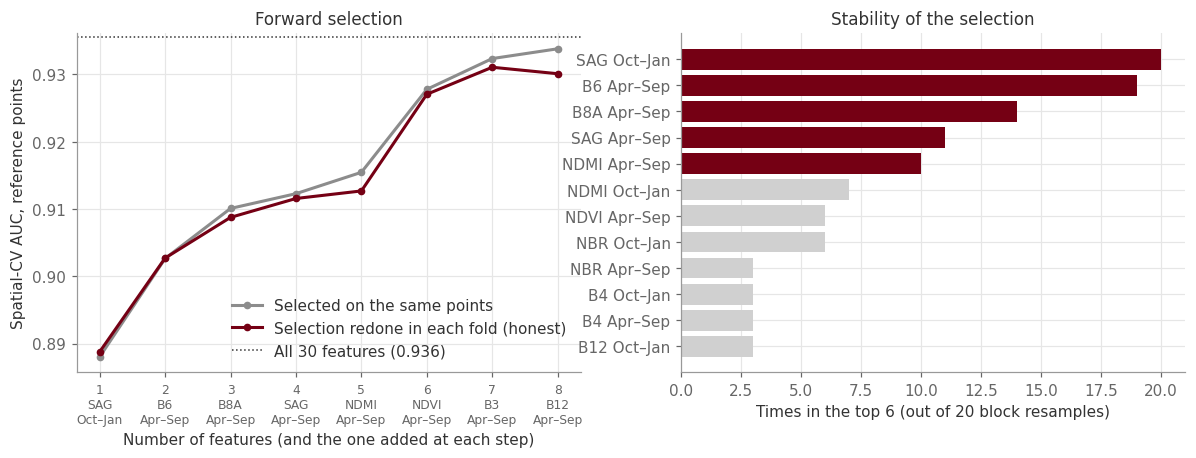

In [11]:
rng = np.random.default_rng(SEED)
blocks = np.unique(g_r)
cnt = Counter()
for _ in range(20):
    pick = rng.choice(blocks, len(blocks), replace=True)
    idx = np.concatenate([np.where(g_r == b)[0] for b in pick])
    gb = np.concatenate([np.full((g_r == b).sum(), i) for i, b in enumerate(pick)])
    cnt.update(c for c, _ in forward(fr.iloc[idx].reset_index(drop=True), gb, k_max=6, seeds=range(2)))
stab = pd.Series(cnt).sort_values(ascending=False).head(12).rename("in top 6 (of 20 resamples)")

drop = pd.Series({NAME[b]: cv_auc(fr, [c for c in CAND if not c.startswith(b + "_")], g_r) - a_full for b in SROWS},
                 name="AUC change when dropped").sort_values()
display(stab.to_frame())
display(drop.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(sel.index, sel.iloc[:, 1], color=PAL["grey"], marker="o", ms=4, label="Selected on the same points")
ax.plot(sel.index, sel.iloc[:, 2], color=PAL["plantation"], marker="o", ms=4, label="Selection redone in each fold (honest)")
ax.axhline(a_full, color=PAL["ink"], ls=":", lw=1, label=f"All 30 features ({a_full:.3f})")
ax.set_xticks(sel.index, [f"{k}\n{c.rsplit('_', 1)[0]}\n{c.rsplit('_', 1)[1].replace('octjan', 'Oct–Jan').replace('winter', 'Apr–Sep')}"
                          for k, c in zip(sel.index, sel.iloc[:, 0])], fontsize=8)
ax.set_xlabel("Number of features (and the one added at each step)")
ax.set_ylabel("Spatial-CV AUC, reference points")
ax.set_title("Forward selection")
ax.legend(loc="lower right")
ax = axes[1]
s = stab.iloc[::-1]
ax.barh(range(len(s)), s.values, color=[PAL["plantation"] if v >= 10 else PAL["light"] for v in s.values])
ax.set_yticks(range(len(s)), [i.replace("_octjan", " Oct–Jan").replace("_winter", " Apr–Sep") for i in s.index])
ax.set_xlabel("Times in the top 6 (out of 20 block resamples)")
ax.set_title("Stability of the selection")
savefig(fig, "04e_feature_selection")
plt.show()

### The short list, tested
We take the first six features of the stable path and compare them with SAG alone and with all 30
features. Each is scored in three ways: spatial CV on the reference points, spatial CV on QC, and trained on
reference then tested on QC (cutoff from the reference points, as in (iv)). We also try replacing B6 and
B8A with one simple red-edge ratio, (B8A − B6) / (B8A + B6), which would be easier to explain.

In [12]:
for f in (fr, fq):
    f["RE_winter"] = (f["B8A_winter"] - f["B6_winter"]) / (f["B8A_winter"] + f["B6_winter"])
SHORT = [c for c, _ in path[:6]]
SETS2 = {"SAG Oct–Jan only": ["SAG_octjan"],
         "First 3 of the path": SHORT[:3],
         f"Short list ({len(SHORT)})": SHORT,
         "Short list, B6 + B8A replaced by red-edge ratio": [c for c in SHORT if c not in ("B6_winter", "B8A_winter")] + ["RE_winter"],
         "All 30 season features": CAND}
rows = []
for name, cols in SETS2.items():
    rr, _ = cv_evaluate(fr[cols].values, fr.y.values, groups=g_r, kind="group", seeds=range(20))
    rq, _ = cv_evaluate(fq[cols].values, fq.y.values, groups=g_q, kind="group", seeds=range(20))
    _, oof = cv_evaluate(fr[cols].values, fr.y.values, groups=g_r, kind="group", seeds=[SEED])
    t = threshold_hiding_at_most(oof[SEED][fr.y.values == 0], 0.05)
    p = make_model().fit(fr[cols].values, fr.y.values).predict_proba(fq[cols].values)[:, 1]
    a, lo, hi = auc_ci(fq.y.values, p, n_boot=N_BOOT, seed=SEED)
    flag = p >= t
    rows.append({"features": name, "n": len(cols),
                 "ref AUC": rr.auc.mean(), "ref caught %": rr.nest_caught.mean(),
                 "QC AUC": rq.auc.mean(), "QC caught %": rq.nest_caught.mean(), "QC hidden %": rq.nest_hidden.mean(),
                 "ref→QC AUC": a, "ref→QC 95% CI": f"{lo:.2f}–{hi:.2f}",
                 "ref→QC caught %": 100 * flag[fq.y.values == 1].mean(), "ref→QC hidden %": 100 * flag[fq.y.values == 0].mean()})
short = pd.DataFrame(rows).set_index("features")
print("Short list:", SHORT)
print(f"QC forests scored: {int((fq.y == 0).sum())}; one forest = {100 / (fq.y == 0).sum():.1f} points of 'hidden'")
short

Short list: ['SAG_octjan', 'B6_winter', 'B8A_winter', 'SAG_winter', 'NDMI_winter', 'NDVI_winter']
QC forests scored: 115; one forest = 0.9 points of 'hidden'


,n,ref AUC,ref caught %,QC AUC,QC caught %,QC hidden %,ref→QC AUC,ref→QC 95% CI,ref→QC caught %,ref→QC hidden %
features,,,,,,,,,,
SAG Oct–Jan only,1,0.889,52.155,0.849,34.553,5.130,0.863,0.82–0.90,57.616,13.043
First 3 of the path,3,0.911,64.023,0.888,53.858,5.087,0.901,0.87–0.93,72.185,12.174
Short list (6),6,0.928,74.052,0.902,59.156,5.435,0.904,0.87–0.94,73.510,9.565
"Short list, B6 + B8A replaced by red-edge ratio",5,0.922,72.347,0.905,60.331,6.348,0.886,0.84–0.92,59.934,9.565
All 30 season features,30,0.936,77.529,0.922,58.079,5.870,0.923,0.89–0.95,77.152,7.826


In [13]:
# Standardised coefficients of the short-list model on the reference points, with bootstrap 95% CIs.
# B6 and B8A in winter are almost the same measurement (correlation shown), so read them as a pair.
print(f"correlation of B6 and B8A (Apr–Sep), reference points: {fr[['B6_winter', 'B8A_winter']].corr().iloc[0, 1]:.2f}")
bootstrap_coefs(fr[SHORT].values, fr.y.values, SHORT, n_boot=N_BOOT, seed=SEED)

correlation of B6 and B8A (Apr–Sep), reference points: 0.98


,coef,ci_low,ci_high
SAG_octjan,1.577,1.310,1.877
B6_winter,2.438,1.685,3.205
B8A_winter,-1.672,-2.362,-0.947
SAG_winter,0.664,0.376,0.979
NDMI_winter,1.485,1.170,1.824
NDVI_winter,-1.287,-1.651,-0.951


## (vi) What this shows
**1. SAG is still the best single signal, and its best months are Oct–Dec.** No band in any month beats
it. Its best cell is November (AUC 0.89 on the reference points, 0.88 on QC), slightly ahead of Cropin's
Dec–Jan core (0.85 / 0.83). This agrees with Nathan's finding that spring SAG is a little stronger.

**2. SWIR (B11, B12), the bands Deepak named, carry a real but modest signal, and it isn't seasonal.**
Plantations are darker in SWIR in every month. The best AUC is about 0.71 (B11) and 0.68 (B12) on the
reference points and 0.65–0.73 on QC, and Dec–Jan isn't special. **Adding B11 and B12 to SAG barely moves
the model** (AUC +0.006 on both sets), as Nathan also found for B11. So SWIR mostly repeats what SAG
already sees.

**3. The useful extra information is in the other bands, in two different seasons.**
- **Spring and summer (Oct–Dec):** red edge and near-infrared (B6–B8A) are lower in plantations, with AUC
  0.77–0.79 on the reference points. On QC they're weaker (0.63–0.68).
- **Winter (May–Jul):** the moisture and red-edge indices (NDMI, NBR, NDRE) flip to *higher* in plantations,
  with AUC about 0.70 on the reference points and 0.75–0.80 on QC. In Oct–Jan they're close to useless. So
  the winter window adds something the summer window doesn't.

**4. The pattern is general, not a QC quirk.** Across the 180 cells, the reference and QC AUCs agree
closely (Spearman ρ 0.78). 98% of the cells significant on both sets point the same way.

**5. All 10 bands over both seasons improve on SAG alone.**

| | AUC, SAG only → all bands | Plantations caught at ≈ 5% forest hidden |
|---|---|---|
| Reference points, spatial CV | 0.89 → **0.93** | 53% → **76%** |
| QC polygons, spatial CV (exploratory) | 0.85 → **0.92** | 35% → **62%** |
| Trained on reference, tested on QC | 0.86 → **0.92** [0.89–0.95] | 56% → **76%** |

Even without SAG, the raw bands reach AUC 0.92 / 0.91, so the information is in the spectrum itself.

**6. The cutoff still doesn't transfer.** When the reference-set cutoff is applied to QC, it hides **9–10%
of QC forest instead of 5%**. That's 10–12 of the 115 forests scored, so the uncertainty is wide. This is
the same problem notebook 03 found with SAG. The extra bands improve the ranking, but the operating cutoff
still has to be set on a sample of real alerts. The "hidden" share is also fragile. SAG alone gives 10% in
(iv) and 13% in (v), because the two sections drop a slightly different set of points with missing values.
That's 3 forests.

**7. Six features keep most of the gain.** Forward selection on the reference points gives a stable short
list:

| Feature | What it captures | Picked in top 6 |
|---|---|---|
| SAG Oct–Jan | Cropin's dark-green signal | 20/20 resamples |
| B6 red edge 2, Apr–Sep | winter red edge, read as a pair with B8A | 19/20 |
| B8A narrow NIR, Apr–Sep | winter near-infrared | 14/20 |
| SAG Apr–Sep | the dark-green signal in winter | 11/20 |
| NDMI Apr–Sep | winter canopy moisture (higher in plantations) | 10/20 |
| NDVI Apr–Sep | winter greenness (read together with NDMI) | 6/20 |

- **Reference points:** AUC 0.928, against 0.936 for all 30 features.
- **QC:** 0.902, against 0.922.
- **Trained on reference, tested on QC:** 0.904 [0.87–0.94], with 74% of QC plantations caught, against
  0.923 and 77% for all 30.
- **The estimate isn't inflated by the selection.** With the selection redone inside each fold, the
  6-feature AUC is 0.927.
- **Where the gain comes from.** Five of the six are **winter** features, so most of what SAG misses is in
  the Apr–Sep season, not in SWIR. B6 and B8A are 98% correlated, so the model uses the gap between them
  (B6 high relative to B8A in plantations), not either band alone.
- **A simple ratio doesn't do the same job.** Replacing the pair with a red-edge ratio loses ground on the
  transfer test (0.886, 60% caught), so the two bands stay.
- **SWIR's role is small.** B12 Apr–Sep is the 8th pick and adds nothing honest (0.930 vs 0.931 at step 7).
  In the drop-one check, removing B11 or B12 from the full model changes AUC by less than 0.001. Only B6
  and SAG cost more than 0.005 when dropped.

**Caveats.**
- Monthly values are medians pooled over 2019–2022, and the indices are built from those medians.
- The large models are highly correlated, so their coefficients shouldn't be read one by one. Even in the
  short list, B6 and B8A only make sense as a pair.
- The short list was chosen by forward selection on the reference points, so the reference AUCs are
  slightly optimistic. The fold-wise check and the QC test show the effect is small.
- On QC, the nested cutoff hides slightly more than 5% (5.0–5.7%), because 5% of 115 forests is about 6
  polygons.
- Everything on the QC set is exploratory.

**Next steps.**
1. Compare this 6-feature list with Nathan's Lean-4 (SAG Sep–Nov, SAG phase, summer NDMI, Oct–Jan NDVI)
   and Julia's models on the same splits, and agree one shared feature table. They overlap on SAG, NDMI and
   NDVI. What's new here is winter red edge.
2. Check whether the winter red-edge signal holds within each state, and for eucalyptus vs pine.
3. Set the operating cutoff on a sample of real alerts (open request to Cropin).